# Кто купит снова? Lamoda & ЦУ

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

orders = pd.read_parquet("orders.parquet")
orders["order_date"] = pd.to_datetime(orders["order_date"])

train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

orders.head(20)

,customer_id,order_id,order_date,product_id,paid_price,loyalty_percent,discount_percent
0,40087,570457,2021-11-25,228681,57.3761,25.0,0.0
1,40087,570457,2021-11-25,495124,14.0784,25.0,30.0
2,88229,13093,2021-04-07,495124,25.8780,7.0,0.0
3,11787,6919,2021-04-13,495124,27.8213,0.0,0.0
4,40087,570457,2021-11-25,77643,32.6166,25.0,40.0
5,40087,534928,2021-05-07,536068,46.8628,20.0,50.0
6,40087,534928,2021-05-07,137506,87.9096,20.0,45.0
7,40087,534928,2021-05-07,528450,67.5540,20.0,45.0
8,40087,269569,2021-09-23,524525,144.6986,25.0,0.0
9,38619,11441,2021-10-30,524525,160.1331,17.0,0.0


## 1. EDA

### 1.1 orders: структура и качество данных

In [2]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1213206 entries, 0 to 1213205
Data columns (total 7 columns):
 #   Column            Non-Null Count    Dtype         
---  ------            --------------    -----         
 0   customer_id       1213206 non-null  int64         
 1   order_id          1213206 non-null  int64         
 2   order_date        1213206 non-null  datetime64[ns]
 3   product_id        1213206 non-null  int64         
 4   paid_price        1213206 non-null  float64       
 5   loyalty_percent   1213206 non-null  float64       
 6   discount_percent  1213206 non-null  float64       
dtypes: datetime64[ns](1), float64(3), int64(3)
memory usage: 64.8 MB


In [3]:
print("Период:", orders["order_date"].min(), "-", orders["order_date"].max())
print("Дублей строк:", orders.duplicated().sum())
print("Заказов с несколькими клиентами:", (orders.groupby("order_id")["customer_id"].nunique() > 1).sum())
print("Заказов с несколькими датами:", (orders.groupby("order_id")["order_date"].nunique() > 1).sum())
print("Позиций с нулевой ценой:", (orders["paid_price"] <= 0).sum())
orders.nunique()

Период: 2019-12-18 00:00:00 - 2022-03-18 00:00:00
Дублей строк: 0
Заказов с несколькими клиентами: 0
Заказов с несколькими датами: 0
Позиций с нулевой ценой: 3


customer_id         100000
order_id            626407
order_date             822
product_id          564710
paid_price           19502
loyalty_percent         47
discount_percent        82
dtype: int64

### 1.2 orders: товарная позиция (цена, скидка, лояльность)

In [4]:
print("Доля позиций со скидкой:", round((orders["discount_percent"] > 0).mean(), 3))
print("Доля позиций с лояльностью:", round((orders["loyalty_percent"] > 0).mean(), 3))
orders[["paid_price", "discount_percent", "loyalty_percent"]].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).round(2)

Доля позиций со скидкой: 0.623
Доля позиций с лояльностью: 0.364


,paid_price,discount_percent,loyalty_percent
count,1213206.00,1213206.00,1213206.00
mean,39.59,22.15,5.14
std,48.79,21.93,7.72
min,0.00,0.00,0.00
25%,12.57,0.00,0.00
50%,24.94,20.00,0.00
75%,47.42,40.00,10.00
90%,86.12,54.00,17.00
99%,234.73,74.00,25.00
max,1866.40,81.00,56.00


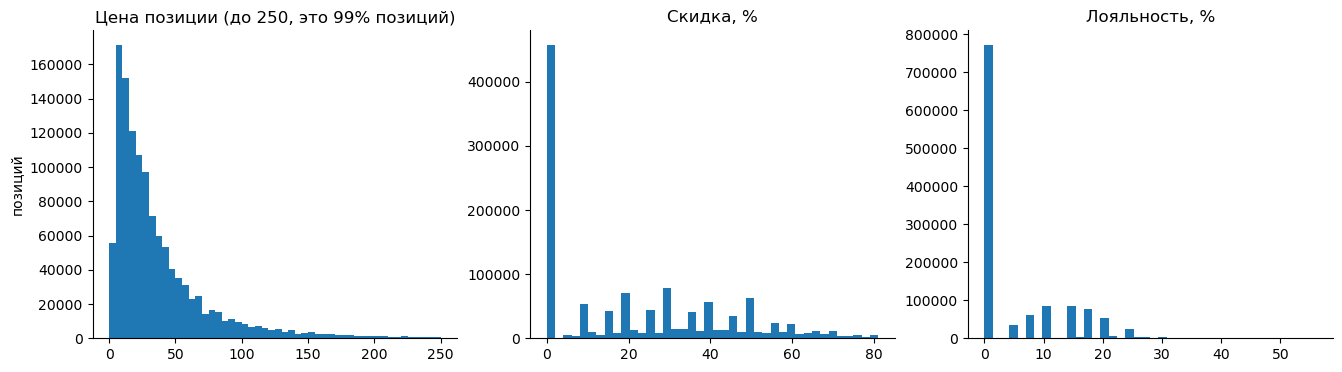

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(orders["paid_price"][orders["paid_price"] < 250], bins=50)
axes[0].set_title("Цена позиции (до 250, это 99% позиций)")
axes[0].set_ylabel("позиций")

axes[1].hist(orders["discount_percent"], bins=40)
axes[1].set_title("Скидка, %")

axes[2].hist(orders["loyalty_percent"], bins=40)
axes[2].set_title("Лояльность, %")

plt.show()

### 1.3 orders: заказ (размер и сумма)

In [6]:
order_stats = orders.groupby("order_id").agg(позиций=("product_id", "count"), сумма=("paid_price", "sum"))
order_stats.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).round(2)

,позиций,сумма
count,626407.00,626407.00
mean,1.94,76.67
std,1.51,88.08
min,1.00,0.01
25%,1.00,27.32
50%,1.00,50.30
75%,2.00,93.67
90%,4.00,163.67
99%,8.00,422.21
max,78.00,3334.40


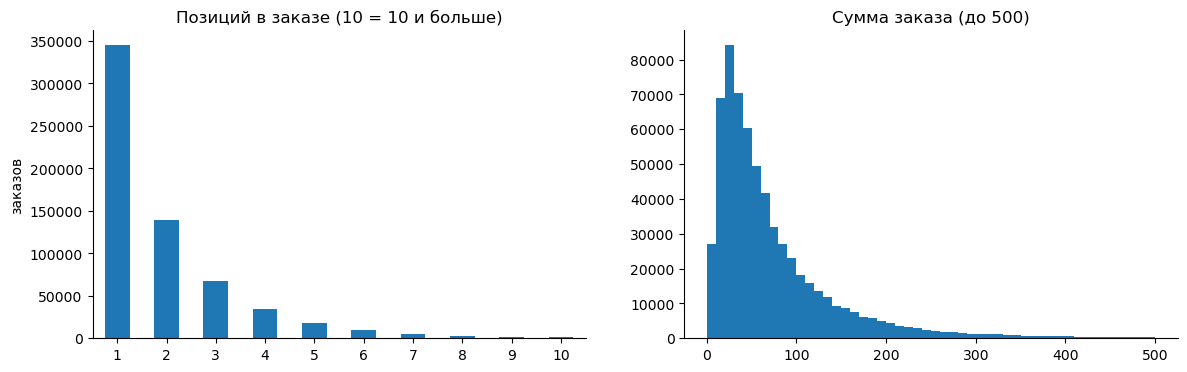

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

order_stats["позиций"].clip(upper=10).value_counts().sort_index().plot.bar(ax=axes[0], rot=0)
axes[0].set_title("Позиций в заказе (10 = 10 и больше)")
axes[0].set_xlabel("")
axes[0].set_ylabel("заказов")

axes[1].hist(order_stats["сумма"][order_stats["сумма"] < 500], bins=50)
axes[1].set_title("Сумма заказа (до 500)")

plt.show()

### 1.4 orders: клиент (частота покупок)

In [8]:
customer_orders = orders.groupby("customer_id")["order_id"].nunique()
print(customer_orders.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).round(2))
pd.cut(customer_orders, bins=[0, 1, 2, 5, 10, 20, 100]).value_counts(normalize=True).sort_index().round(2)

count    100000.00
mean          6.26
std           9.77
min           1.00
25%           1.00
50%           3.00
75%           7.00
90%          16.00
99%          53.00
max          77.00
Name: order_id, dtype: float64


order_id
(0, 1]       0.34
(1, 2]       0.16
(2, 5]       0.21
(5, 10]      0.13
(10, 20]     0.09
(20, 100]    0.07
Name: proportion, dtype: float64

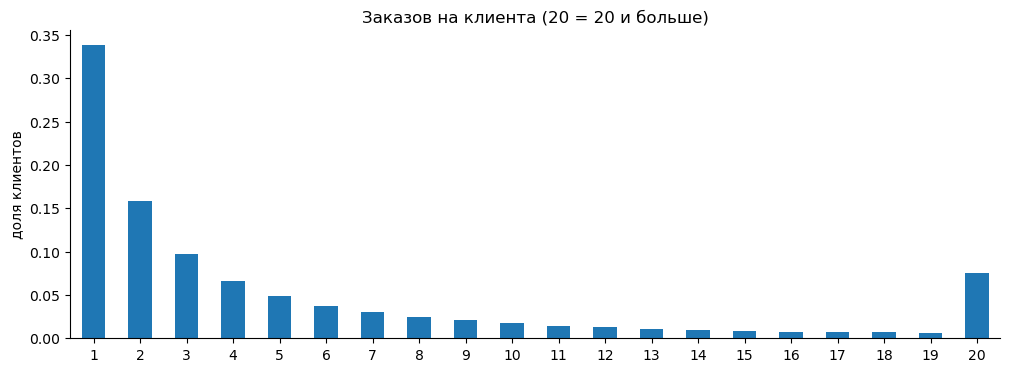

In [9]:
customer_orders.clip(upper=20).value_counts(normalize=True).sort_index().plot.bar(figsize=(12, 4), rot=0)
plt.title("Заказов на клиента (20 = 20 и больше)")
plt.xlabel("")
plt.ylabel("доля клиентов")
plt.show()

### 1.5 orders: динамика по месяцам

In [10]:
orders["month"] = orders["order_date"].dt.to_period("M")
monthly = orders.groupby("month").agg(
    заказов=("order_id", "nunique"),
    клиентов=("customer_id", "nunique"),
    выручка=("paid_price", "sum"),
).round(0)
monthly.head(15)

,заказов,клиентов,выручка
month,,,
2019-12,2030,1459,134556.0
2020-01,5356,3434,343554.0
2020-02,9597,5978,622538.0
2020-03,12889,7846,893746.0
2020-04,13173,7657,964887.0
2020-05,17304,9871,1311140.0
2020-06,20094,11384,1418105.0
2020-07,17927,10659,1168204.0
2020-08,18652,10822,1233305.0


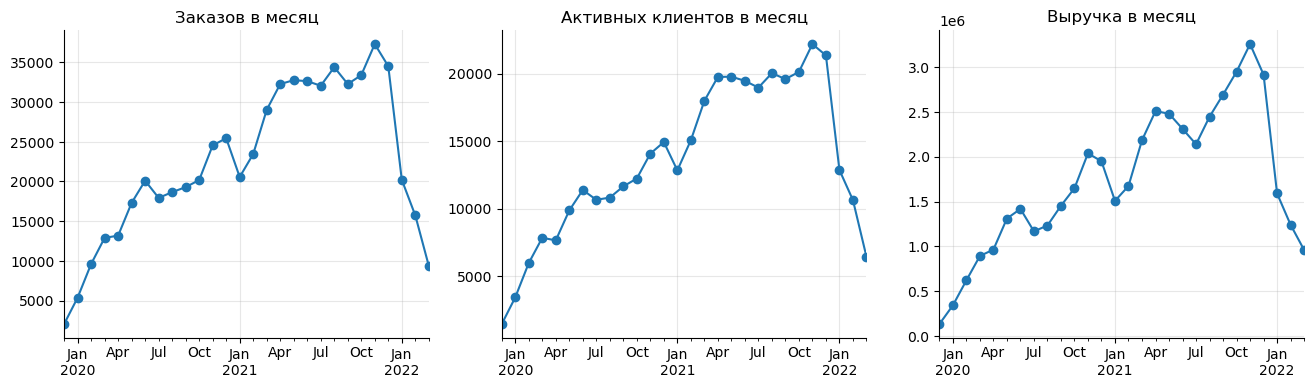

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

monthly["заказов"].plot(ax=axes[0], marker="o")
axes[0].set_title("Заказов в месяц")

monthly["клиентов"].plot(ax=axes[1], marker="o")
axes[1].set_title("Активных клиентов в месяц")

monthly["выручка"].plot(ax=axes[2], marker="o")
axes[2].set_title("Выручка в месяц")

for ax in axes:
    ax.set_xlabel("")
    ax.grid(alpha=0.3)

plt.show()

Спад с января 2022 - не реальное падение продаж, а следствие обрезки истории под дату скоринга каждого клиента (см. 1.7).

### 1.6 train и test

In [12]:
print("train:", train.shape, "test:", test.shape)
print("Клиентов, которые есть и в train, и в test:", train["customer_id"].isin(test["customer_id"]).sum())
print("Повторов клиентов в train:", train["customer_id"].duplicated().sum())
print("Даты скоринга в test:", test["scoring_date"].unique())
print("Доля target = 1:", round(train["target"].mean(), 3))

train.groupby("scoring_date")["target"].agg(["count", "mean"]).round(3)

train: (75000, 3) test: (25000, 2)
Клиентов, которые есть и в train, и в test: 0
Повторов клиентов в train: 0
Даты скоринга в test: ['2022-04-01']
Доля target = 1: 0.34


,count,mean
scoring_date,,
2022-01-01,25000,0.348
2022-02-01,25000,0.334
2022-03-01,25000,0.339


### 1.7 Окно истории для каждой даты скоринга

In [13]:
history = orders.merge(pd.concat([train, test]), on="customer_id")
history["days_before"] = (pd.to_datetime(history["scoring_date"]) - history["order_date"]).dt.days

history.groupby("scoring_date").agg(
    клиентов=("customer_id", "nunique"),
    первый_заказ=("order_date", "min"),
    последний_заказ=("order_date", "max"),
    мин_дней_до_скоринга=("days_before", "min"),
    макс_дней_до_скоринга=("days_before", "max"),
)

,клиентов,первый_заказ,последний_заказ,мин_дней_до_скоринга,макс_дней_до_скоринга
scoring_date,,,,,
2022-01-01,25000,2019-12-18,2021-12-18,14,745
2022-02-01,25000,2020-01-18,2022-01-18,14,745
2022-03-01,25000,2020-02-15,2022-02-15,14,745
2022-04-01,25000,2020-03-18,2022-03-18,14,744


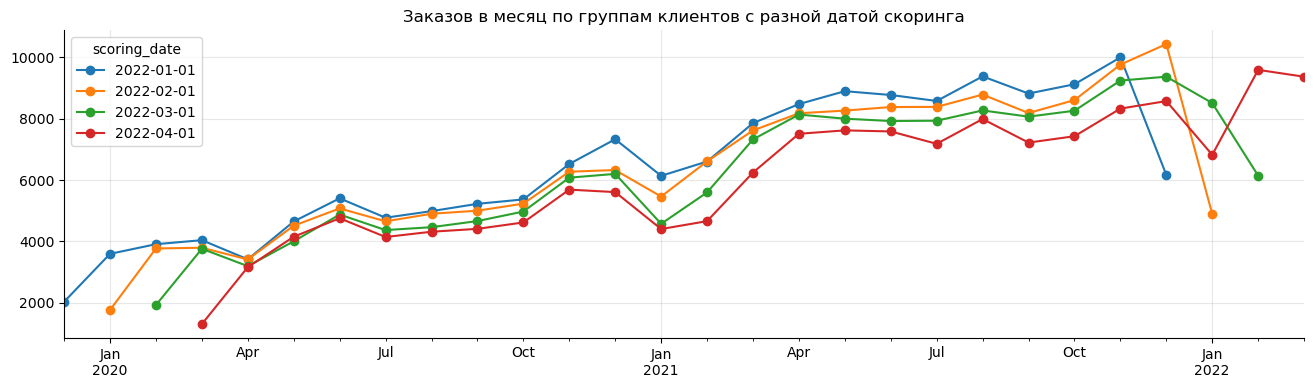

In [14]:
history.groupby(["month", "scoring_date"])["order_id"].nunique().unstack().plot(figsize=(16, 4), marker="o")
plt.title("Заказов в месяц по группам клиентов с разной датой скоринга")
plt.xlabel("")
plt.grid(alpha=0.3)
plt.show()

**Итоги по train, test и окну истории:**

- В train 75 000 клиентов, каждый ровно один раз. Три даты скоринга по 25 000 клиентов: 2022-01-01, 2022-02-01, 2022-03-01.
- В test 25 000 клиентов с одной датой 2022-04-01. С train не пересекаются.
- Доля target = 1 около 34% и почти не меняется от даты к дате.
- **История в orders уже обрезана под каждого клиента:** от scoring_date - 745 дней до scoring_date - 14 дней.
- Для валидации удобно делить train по scoring_date: например, обучаться на январе и феврале, проверяться на марте.

### 1.8 products: справочник товаров

In [15]:
products = pd.read_parquet("products.parquet")

print(products.shape)
print("Все товары из orders есть в products:", orders["product_id"].isin(products["product_id"]).all())
print(products.nunique())
products.head(20)

(564710, 5)
Все товары из orders есть в products: True
product_id        564710
brand               4505
category               7
category2            103
gender_product         3
dtype: int64


,product_id,brand,category,category2,gender_product
0,197963,brand_046,CLOTHES,TROUSERS & JUMPSUITS,MEN+UNISEX
1,114253,brand_046,CLOTHES,TRACKSUITS,MEN+UNISEX
2,395617,brand_046,CLOTHES,TROUSERS & JUMPSUITS,MEN+UNISEX
3,102170,brand_054,PERFUME & BEAUTY,SHAVING & DEPILATION,MEN+UNISEX
4,206029,brand_055,FOOTWEAR,SANDALS,KIDS
5,12756,brand_4222,FOOTWEAR,SANDALS,KIDS
6,370410,brand_4222,FOOTWEAR,SPORT SHOES,KIDS
7,263667,brand_4222,FOOTWEAR,BOOTS,KIDS
8,476817,brand_4222,FOOTWEAR,BOOTS,KIDS
9,215260,brand_4222,FOOTWEAR,SPORT SHOES,KIDS


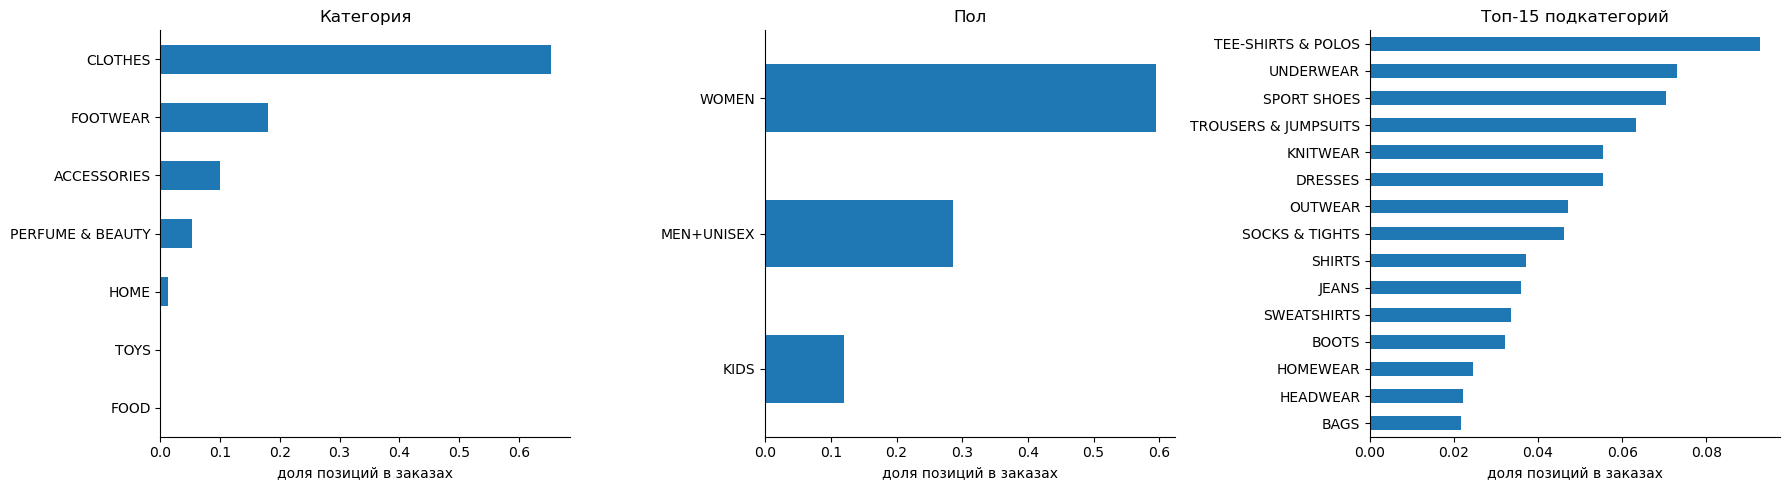

Доля позиций у топ-10 брендов: 0.203
Доля позиций у топ-100 брендов: 0.577


In [16]:
items = orders.merge(products, on="product_id")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

items["category"].value_counts(normalize=True).sort_values().plot.barh(ax=axes[0], title="Категория")
items["gender_product"].value_counts(normalize=True).sort_values().plot.barh(ax=axes[1], title="Пол")
items["category2"].value_counts(normalize=True).head(15).sort_values().plot.barh(ax=axes[2], title="Топ-15 подкатегорий")

for ax in axes:
    ax.set_ylabel("")
    ax.set_xlabel("доля позиций в заказах")

plt.tight_layout()
plt.show()

print("Доля позиций у топ-10 брендов:", round(items["brand"].value_counts(normalize=True).head(10).sum(), 3))
print("Доля позиций у топ-100 брендов:", round(items["brand"].value_counts(normalize=True).head(100).sum(), 3))

**Итоги по products:**

- 564 710 товаров, пропусков нет, все товары из orders есть в справочнике.
- 7 категорий, 103 подкатегории, 3 значения пола, 4 505 брендов.
- Больше всего покупают одежду (около 65% позиций), затем обувь (18%) и аксессуары (10%).
- Женские товары около 60% позиций, мужские и унисекс около 29%, детские около 12%.
- Бренды сильно размазаны: топ-10 дают 20% позиций, топ-100 дают 58%. Брать бренд как признак напрямую не стоит, лучше считать, например, число разных брендов у клиента.

In [17]:
items.sort_values(by = 'customer_id').head(60)

,customer_id,order_id,order_date,product_id,paid_price,loyalty_percent,discount_percent,month,brand,category,category2,gender_product
503236,1,190937,2020-07-31,16824,12.5685,0.0,50.0,2020-07,brand_3754,FOOTWEAR,SPORT SHOES,WOMEN
1196175,1,54132,2021-12-14,439096,11.0726,0.0,60.0,2021-12,brand_1284,CLOTHES,TEE-SHIRTS & POLOS,MEN+UNISEX
806016,1,54132,2021-12-14,203473,12.4427,0.0,51.0,2021-12,brand_1758,CLOTHES,TEE-SHIRTS & POLOS,MEN+UNISEX
849954,1,55861,2021-12-20,365023,14.1203,0.0,67.0,2021-12,brand_3289,CLOTHES,SWEATSHIRTS,MEN+UNISEX
496615,2,83823,2021-08-28,276598,6.5149,0.0,63.0,2021-08,brand_3317,CLOTHES,HOMEWEAR,KIDS
1203786,2,83823,2021-08-28,379152,7.8990,0.0,26.0,2021-08,brand_3317,CLOTHES,TEE-SHIRTS & POLOS,KIDS
354626,3,198029,2021-04-20,316319,154.3452,0.0,35.0,2021-04,brand_1055,CLOTHES,TRACKSUITS,MEN+UNISEX
446697,3,198029,2021-04-20,124662,34.9374,0.0,22.0,2021-04,brand_2995,FOOTWEAR,SPORT SHOES,MEN+UNISEX
130611,3,352948,2021-04-27,261627,18.0349,0.0,30.0,2021-04,brand_1155,CLOTHES,TEE-SHIRTS & POLOS,MEN+UNISEX
880261,3,352948,2021-04-27,242913,60.1023,0.0,0.0,2021-04,brand_2725,CLOTHES,TROUSERS & JUMPSUITS,MEN+UNISEX


## 2. Признаки

Сворачиваем историю каждого клиента в одну строку агрегатов. История в orders уже обрезана под scoring_date, поэтому фильтровать заказы по дате не нужно.

### 2.1 Подготовка данных

К items добавляем scoring_date клиента и считаем, за сколько дней до неё был сделан каждый заказ.

In [18]:
clients = pd.concat([train, test])[["customer_id", "scoring_date"]]

data = items.merge(clients, on="customer_id")
data["days_before"] = (pd.to_datetime(data["scoring_date"]) - data["order_date"]).dt.days
data["has_discount"] = data["discount_percent"] > 0

data.shape

(1213206, 15)

### 2.2 Базовые признаки: частота, давность, деньги, скидки, разнообразие

- days_since_last / days_since_first: сколько дней от последнего / первого заказа до scoring_date
- avg_days_between: средний интервал между заказами
- last_to_avg_gap: давность последнего заказа относительно привычного интервала клиента. Если значение сильно больше 1, клиент "задерживается" с покупкой

In [19]:
features = data.groupby("customer_id").agg(
    orders_cnt=("order_id", "nunique"),
    items_cnt=("product_id", "count"),
    total_sum=("paid_price", "sum"),
    avg_item_price=("paid_price", "mean"),
    days_since_last=("days_before", "min"),
    days_since_first=("days_before", "max"),
    share_discount=("has_discount", "mean"),
    avg_discount=("discount_percent", "mean"),
    avg_loyalty=("loyalty_percent", "mean"),
    max_loyalty=("loyalty_percent", "max"),
    brands_cnt=("brand", "nunique"),
    category2_cnt=("category2", "nunique"),
)

features["avg_order_sum"] = features["total_sum"] / features["orders_cnt"]
features["items_per_order"] = features["items_cnt"] / features["orders_cnt"]
features["avg_days_between"] = (features["days_since_first"] - features["days_since_last"]) / (features["orders_cnt"] - 1)
features["last_to_avg_gap"] = features["days_since_last"] / (features["avg_days_between"] + 1)

features.head()

,orders_cnt,items_cnt,total_sum,avg_item_price,days_since_last,days_since_first,share_discount,avg_discount,avg_loyalty,max_loyalty,brands_cnt,category2_cnt,avg_order_sum,items_per_order,avg_days_between,last_to_avg_gap
customer_id,,,,,,,,,,,,,,,,
1,3,4,50.2041,12.551025,43,550,1.000000,57.000,0.000000,0.0,4,3,16.73470,1.333333,253.50,0.168959
2,1,2,14.4139,7.206950,185,185,1.000000,44.500,0.000000,0.0,1,2,14.41390,2.000000,NaN,NaN
3,2,8,477.0859,59.635737,249,256,0.625000,17.125,0.000000,0.0,6,5,238.54295,4.000000,7.00,31.125000
4,5,8,435.8433,54.480412,90,225,0.375000,14.375,1.750000,7.0,5,6,87.16866,1.600000,33.75,2.589928
5,6,18,1427.9442,79.330233,239,420,0.333333,7.000,3.222222,15.0,12,8,237.99070,3.000000,36.20,6.424731


### 2.3 Активность за последние 30, 90, 180 и 365 дней

Окно отсчитывается от последней доступной даты истории, то есть от scoring_date - 14 дней.

In [20]:
for d in [30, 90, 180, 365]:
    recent = data[data["days_before"] <= d + 14]
    features[f"orders_{d}d"] = recent.groupby("customer_id")["order_id"].nunique()
    features[f"sum_{d}d"] = recent.groupby("customer_id")["paid_price"].sum()
    features[f"orders_{d}d"] = features[f"orders_{d}d"].fillna(0)
    features[f"sum_{d}d"] = features[f"sum_{d}d"].fillna(0)

features[["orders_30d", "orders_90d", "orders_180d", "orders_365d"]].describe().round(2)

,orders_30d,orders_90d,orders_180d,orders_365d
count,100000.00,100000.00,100000.00,100000.00
mean,0.46,1.15,2.14,4.02
std,1.01,2.08,3.55,6.05
min,0.00,0.00,0.00,1.00
25%,0.00,0.00,0.00,1.00
50%,0.00,1.00,1.00,2.00
75%,1.00,1.00,2.00,4.00
max,36.00,47.00,74.00,74.00


### 2.4 Доли категорий и пола в покупках клиента

In [21]:
category_share = pd.crosstab(data["customer_id"], data["category"], normalize="index").add_prefix("share_")
gender_share = pd.crosstab(data["customer_id"], data["gender_product"], normalize="index").add_prefix("share_")

features = features.join(category_share).join(gender_share)
features.shape

(100000, 34)

### 2.5 Итоговые таблицы для train и test

Пропуски в avg_days_between и last_to_avg_gap только у клиентов с одним заказом: интервала между заказами у них нет. Бустинги умеют работать с такими пропусками.

In [22]:
train_df = train.merge(features, on="customer_id")
test_df = test.merge(features, on="customer_id")

print("train_df:", train_df.shape, "test_df:", test_df.shape)
print("Пропуски:")
print(train_df.isna().sum()[train_df.isna().sum() > 0])
train_df.head()

train_df: (75000, 37) test_df: (25000, 36)
Пропуски:
avg_days_between    24880
last_to_avg_gap     24880
dtype: int64


,customer_id,scoring_date,target,orders_cnt,items_cnt,total_sum,avg_item_price,days_since_last,days_since_first,share_discount,...,share_ACCESSORIES,share_CLOTHES,share_FOOD,share_FOOTWEAR,share_HOME,share_PERFUME & BEAUTY,share_TOYS,share_KIDS,share_MEN+UNISEX,share_WOMEN
0,3,2022-01-01,0,2,8,477.0859,59.635737,249,256,0.625000,...,0.000000,0.750000,0.0,0.250,0.0,0.00,0.0,0.0,1.000000,0.000000
1,14,2022-01-01,0,4,12,505.4243,42.118692,338,601,0.416667,...,0.083333,0.416667,0.0,0.250,0.0,0.25,0.0,0.0,0.083333,0.916667
2,21,2022-01-01,0,1,1,62.8984,62.898400,34,34,0.000000,...,0.000000,0.000000,0.0,1.000,0.0,0.00,0.0,0.0,0.000000,1.000000
3,24,2022-01-01,1,3,8,441.4915,55.186437,242,244,0.750000,...,0.125000,0.750000,0.0,0.125,0.0,0.00,0.0,0.0,1.000000,0.000000
4,26,2022-01-01,1,2,4,206.8980,51.724500,159,609,0.500000,...,0.000000,0.000000,0.0,1.000,0.0,0.00,0.0,0.0,0.000000,1.000000


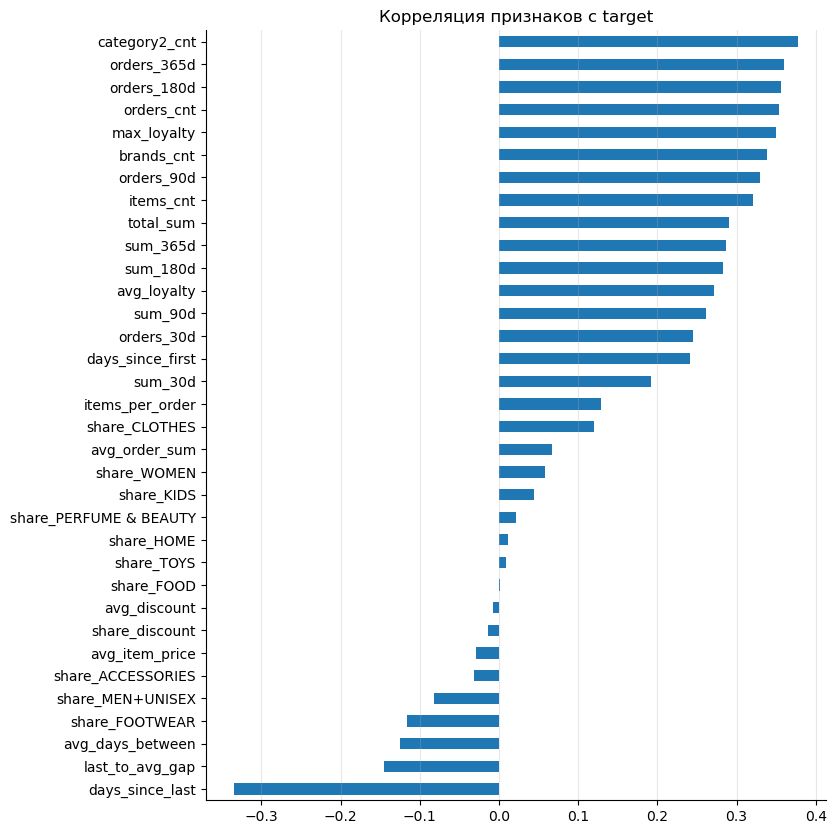

In [23]:
corr = train_df.drop(columns=["customer_id", "scoring_date"]).corr()["target"].drop("target").sort_values()

corr.plot.barh(figsize=(8, 10))
plt.title("Корреляция признаков с target")
plt.grid(axis="x", alpha=0.3)
plt.show()

## 3. Модели

### 3.1 Метрика AP@20%

Сортируем клиентов по score и смотрим только на верхние 20%. Чем выше в списке стоят реальные покупатели, тем больше метрика.

AP@20% = сумма(Precision@i * y_i) / min(K, N_positive), где K = 20% клиентов, сумма по первым K позициям.

In [24]:
import numpy as np
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier


def ap_at_20(y_true, y_score):
    df = pd.DataFrame({"y": y_true, "score": y_score}).sort_values("score", ascending=False)
    k = int(np.ceil(0.2 * len(df)))
    top = df["y"].values[:k]
    precision = top.cumsum() / np.arange(1, k + 1)
    return (precision * top).sum() / min(k, df["y"].sum())

### 3.2 Разбиение на обучение и валидацию

Обучаемся на январе и феврале, проверяемся на марте. Так же устроен test: модель предсказывает для более поздней даты, чем видела при обучении.

In [25]:
X = train_df.drop(columns=["customer_id", "scoring_date", "target"]).fillna(-1)
y = train_df["target"]
is_valid = train_df["scoring_date"] == "2022-03-01"

X_train, y_train = X[~is_valid], y[~is_valid]
X_valid, y_valid = X[is_valid], y[is_valid]

print("train:", X_train.shape, "valid:", X_valid.shape)
print("Идеальный прогноз:", ap_at_20(y_valid, y_valid))
print("Случайный прогноз:", round(ap_at_20(y_valid, np.random.rand(len(y_valid))), 4))
print("Только давность последнего заказа:", round(ap_at_20(y_valid, -X_valid["days_since_last"]), 4))

train: (50000, 34) valid: (25000, 34)
Идеальный прогноз: 1.0
Случайный прогноз: 0.1165
Только давность последнего заказа: 0.2808


### 3.3 Быстрый перебор моделей

Все модели с настройками по умолчанию. Цель - понять, какие модели в целом справляются лучше, и дальше настраивать только их.

In [26]:
models = {
    "LogisticRegression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "RandomForest": RandomForestClassifier(n_estimators=300, min_samples_leaf=20, n_jobs=-1, random_state=42),
    "LightGBM": LGBMClassifier(verbose=-1, random_state=42),
    "XGBoost": XGBClassifier(random_state=42),
    "CatBoost": CatBoostClassifier(iterations=500, verbose=0, random_state=42, allow_writing_files=False),
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict_proba(X_valid)[:, 1]
    results.append({"модель": name, "AP@20%": ap_at_20(y_valid, pred), "ROC-AUC": roc_auc_score(y_valid, pred)})

results = pd.DataFrame(results).sort_values("AP@20%", ascending=False).round(4)
results

,модель,AP@20%,ROC-AUC
2,LightGBM,0.6405,0.8304
4,CatBoost,0.6363,0.8289
3,XGBoost,0.6209,0.8203
1,RandomForest,0.6153,0.8255
0,LogisticRegression,0.5037,0.7886


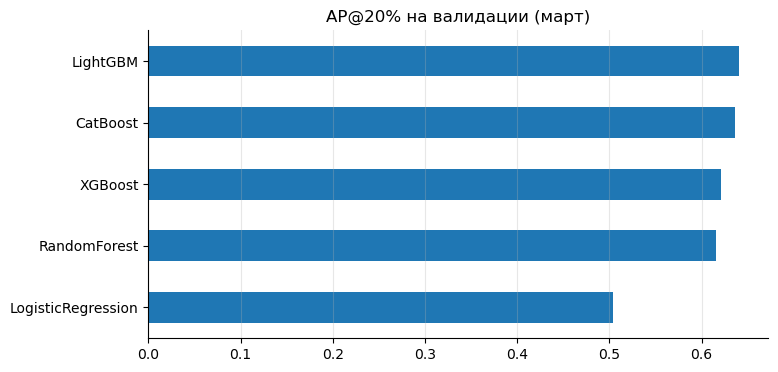

In [27]:
results.sort_values("AP@20%").plot.barh(x="модель", y="AP@20%", legend=False, figsize=(8, 4))
plt.title("AP@20% на валидации (март)")
plt.ylabel("")
plt.grid(axis="x", alpha=0.3)
plt.show()

**Итоги быстрого перебора:**

- Ориентиры: случайный прогноз около 0.12, одна только давность последнего заказа 0.28, идеальный прогноз 1.0.
- Лучше всех LightGBM (0.641) и CatBoost (0.636), разница между ними в пределах шума.
- XGBoost и RandomForest немного хуже (около 0.62), логистическая регрессия заметно отстаёт (0.50).
- Дальше настраиваем LightGBM и CatBoost.

## 4. Признаки ожидаемой даты следующего заказа

Исследование показало, что target в train - не настоящая повторная покупка, а частично построен по правилу. Организаторы считали ожидаемую дату следующего заказа как дату последнего заказа плюс медианный интервал между заказами клиента.

Обозначим e = медианный интервал - дней с последнего заказа. Это число дней после scoring_date, на которое приходится ожидаемый заказ. L - длина окна прогноза: 90 дней для января, 89 для февраля, 92 для марта и 91 для test (апрель).

- e примерно от 8 до L - 10: target = 1;
- e от -14 до 2 (ожидаемый заказ попал в скрытые 14 дней перед scoring_date) или от L до L + 14: target = 0;
- в остальных случаях и у клиентов с одним заказом метка ведёт себя как обычная покупка.

Правило почти точное (98-100%) для простых клиентов: 2-3 заказа или все товары из одной категории. У клиентов с 4+ заказами и разными категориями оно работает слабо.

Отсюда же понятно, почему искусственные даты скоринга ухудшали качество: история в данных настоящая, а target синтетический, и модель училась не тому. Поэтому обучаемся только на реальных метках и на всей истории.

### 4.1 Интервалы между заказами

Один заказ = один order_id. Для каждого заказа считаем, за сколько дней до scoring_date он был (db), и интервалы между соседними заказами клиента. Заказы в один день дают нулевой интервал, их не выбрасываем: организаторы считали так же.

- o_n - число заказов, o_rec - дней с последнего заказа, o_g_med и o_g_max - медиана и максимум интервала;
- e и o_e_max - ожидаемый заказ по медиане и по максимальному интервалу, e_to_end = L - e;
- k_category - число категорий у клиента, simple - флаг простого клиента.

In [28]:
window_days = {"2022-01-01": 90, "2022-02-01": 89, "2022-03-01": 92, "2022-04-01": 91}

o = orders.groupby(["customer_id", "order_id"])["order_date"].first().reset_index()
o = o.merge(clients, on="customer_id")
o["db"] = (pd.to_datetime(o["scoring_date"]) - o["order_date"]).dt.days
o = o.sort_values(["customer_id", "db", "order_id"])
o["gap"] = o.groupby("customer_id")["db"].diff()

rule = o.groupby("customer_id").agg(o_n=("db", "size"), o_rec=("db", "min"), o_g_med=("gap", "median"), o_g_max=("gap", "max"))
rule["L"] = clients.set_index("customer_id")["scoring_date"].map(window_days)
rule["e"] = rule["o_g_med"] - rule["o_rec"]
rule["e_to_end"] = rule["L"] - rule["e"]
rule["o_e_max"] = rule["o_g_max"] - rule["o_rec"]
rule["k_category"] = items.groupby("customer_id")["category"].nunique()
rule["simple"] = ((rule["o_n"] <= 3) | (rule["k_category"] == 1)).astype(int)

rule.head()

,o_n,o_rec,o_g_med,o_g_max,L,e,e_to_end,o_e_max,k_category,simple
customer_id,,,,,,,,,,
1,3,43,253.5,501.0,89,210.5,-121.5,458.0,2,1
2,1,185,NaN,NaN,92,NaN,NaN,NaN,1,1
3,2,249,7.0,7.0,90,-242.0,332.0,-242.0,2,1
4,5,90,35.5,63.0,92,-54.5,146.5,-27.0,3,0
5,6,239,19.0,113.0,89,-220.0,309.0,-126.0,2,0


### 4.2 Как правило выглядит на данных

Доля target = 1 по корзинам e шириной 5 дней, отдельно для простых клиентов и для клиентов с 4+ заказами и разными категориями. Зелёная зона - ожидаемый заказ внутри окна, красная - в скрытых 14 днях.

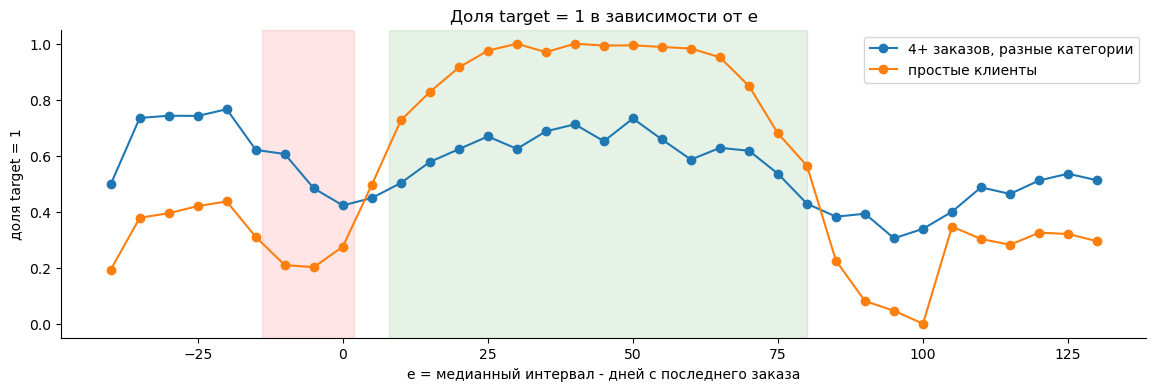

Доля простых клиентов: 0.611
Доля клиентов с одним заказом: 0.332


In [29]:
check = train.merge(rule, left_on="customer_id", right_index=True)
check["e_bin"] = check["e"].clip(-40, 130) // 5 * 5
share = check.pivot_table(index="e_bin", columns="simple", values="target", aggfunc="mean")

share.plot(figsize=(14, 4), marker="o")
plt.axvspan(-14, 2, color="red", alpha=0.1)
plt.axvspan(8, 80, color="green", alpha=0.1)
plt.title("Доля target = 1 в зависимости от e")
plt.xlabel("e = медианный интервал - дней с последнего заказа")
plt.ylabel("доля target = 1")
plt.legend(["4+ заказов, разные категории", "простые клиенты"])
plt.show()

print("Доля простых клиентов:", round(check["simple"].mean(), 3))
print("Доля клиентов с одним заказом:", round((check["o_n"] == 1).mean(), 3))

### 4.3 Дополнительные признаки по интервалам

- o_frac_in и o_frac_gapz - доля интервалов клиента, которые предсказали бы следующий заказ внутри окна или в скрытых 14 днях;
- y_e_med и y_e_mean - то же e, но только по заказам за последний год, через медиану и через среднее.

In [30]:
g = o.dropna(subset=["gap"]).merge(rule["o_rec"], left_on="customer_id", right_index=True)
g["ei"] = g["gap"] - g["o_rec"]
g["is_in"] = (g["ei"] > 10) & (g["ei"] <= 80)
g["is_gapz"] = (g["ei"] > -14) & (g["ei"] <= 10)
rule["o_frac_in"] = g.groupby("customer_id")["is_in"].mean()
rule["o_frac_gapz"] = g.groupby("customer_id")["is_gapz"].mean()

year = o[o["db"] <= 379].copy()
year["gap"] = year.groupby("customer_id")["db"].diff()
rule["y_e_med"] = year.groupby("customer_id")["gap"].median() - rule["o_rec"]
rule["y_e_mean"] = year.groupby("customer_id")["gap"].mean() - rule["o_rec"]

### 4.4 Признаки по категориям

- cover_top - доля заказов, где есть самая частая категория клиента, n_foreign_only - сколько заказов без неё;
- для каждой категории отдельно считаем свой e по датам покупок этой категории. category_n_in - сколько категорий ждут покупку внутри окна, category_best_e - e категории, ближайшее к середине окна.

In [31]:
per_category = items.drop_duplicates(["order_id", "category"]).groupby(["customer_id", "category"]).size()
rule["cover_top"] = per_category.groupby("customer_id").max() / rule["o_n"]
rule["n_foreign_only"] = rule["o_n"] - per_category.groupby("customer_id").max()

c = items[["customer_id", "category", "order_date"]].drop_duplicates().merge(clients, on="customer_id")
c["db"] = (pd.to_datetime(c["scoring_date"]) - c["order_date"]).dt.days
c = c.sort_values(["customer_id", "category", "db"])
c["gap"] = c.groupby(["customer_id", "category"])["db"].diff()

cat = c.groupby(["customer_id", "category"]).agg(rec=("db", "min"), med=("gap", "median")).reset_index()
cat["e_c"] = cat["med"] - cat["rec"]
cat["is_in"] = (cat["e_c"] > 10) & (cat["e_c"] <= 80)
cat["dist"] = (cat["e_c"] - 45).abs()
rule["category_n_in"] = cat.groupby("customer_id")["is_in"].sum()
rule["category_best_e"] = cat.sort_values("dist").groupby("customer_id")["e_c"].first()

### 4.5 Зоны правила

zone - номер зоны по e: 0 - один заказ, 1 - ожидаемый заказ давно просрочен, 2 - скрытые 14 дней, 3 - начало окна, 4 - середина окна, 5 - конец окна, 6 - сразу после окна, 7 - дальше. rel_lo и rel_hi - расстояние до краёв окна в долях медианного интервала.

In [32]:
e = rule["e"]
L = rule["L"]
rule["zone"] = np.select([rule["o_n"] == 1, e <= -14, e <= 2, e <= 12, e <= L - 20, e <= L - 4, e <= L + 14], [0, 1, 2, 3, 4, 5, 6], 7)
rule["rel_lo"] = e / rule["o_g_med"].clip(lower=1)
rule["rel_hi"] = (L - e) / rule["o_g_med"].clip(lower=1)

rule_cols = [col for col in rule.columns if col not in ["o_rec", "L"]]
core_cols = ["o_n", "o_g_med", "e", "e_to_end", "k_category", "simple"]
base_cols = [col for col in train_df.columns if col not in ["customer_id", "scoring_date", "target"]]

train_full = train_df.join(rule[rule_cols], on="customer_id")
test_full = test_df.join(rule[rule_cols], on="customer_id")

print("Новых признаков:", len(rule_cols), "| всего:", len(base_cols + rule_cols))
print("train_full:", train_full.shape, "test_full:", test_full.shape)

Новых признаков: 19 | всего: 53
train_full: (75000, 56) test_full: (25000, 55)


### 4.6 Проверка на кросс-валидации по месяцам

Каждый месяц по очереди уходит в валидацию, обучаемся на двух других и усредняем AP@20%. Так оценка надёжнее, чем по одному марту. Модель - LightGBM с параметрами по умолчанию, чтобы видеть вклад именно признаков.

In [33]:
months = ["2022-01-01", "2022-02-01", "2022-03-01"]


def cv_score(model, cols):
    scores = []
    for month in months:
        is_valid = train_full["scoring_date"] == month
        model.fit(train_full.loc[~is_valid, cols], train_full.loc[~is_valid, "target"])
        pred = model.predict_proba(train_full.loc[is_valid, cols])[:, 1]
        scores.append(ap_at_20(train_full.loc[is_valid, "target"], pred))
    return np.mean(scores)


cv_results = pd.DataFrame({"признаки": ["база из раздела 2", "база + 6 главных", "база + все 19"]})
cv_results["AP@20%"] = [cv_score(LGBMClassifier(verbose=-1, random_state=42), cols) for cols in [base_cols, base_cols + core_cols, base_cols + rule_cols]]
cv_results.round(4)

,признаки,AP@20%
0,база из раздела 2,0.6473
1,база + 6 главных,0.7269
2,база + все 19,0.7433


**Итоги раздела 4:**

- Базовые признаки из раздела 2 дают 0.647 на кросс-валидации по месяцам.
- 6 главных признаков правила поднимают AP@20% до 0.727, все 19 - до 0.743. Это уже выше лучшего результата участников на лидерборде (0.731).
- Главный резерв роста - клиенты с 4+ заказами и разными категориями: для них точное правило найти не удалось.

## 5. Подбор гиперпараметров LightGBM и CatBoost

Подбираем параметры на всех признаках из раздела 4 той же кросс-валидацией по трём месяцам. Считаем на процессоре: на 50 тысячах строк видеокарта медленнее. Первой попыткой в каждом подборе ставим уже известные хорошие параметры, так что результат точно не хуже них. Большого прироста не ждём, около 0.005.

Ячейки 5.1 и 5.2 считаются долго: примерно 10 и 15 минут, верхние пределы 20 и 30 минут.

### 5.1 Подбор LightGBM

До 50 попыток, но не дольше 20 минут.

In [34]:
import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)
feature_cols = base_cols + rule_cols


def lgbm_objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 200, 1500),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 15, 127),
        "min_child_samples": trial.suggest_int("min_child_samples", 10, 200),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.2, 1.0),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 0.001, 10, log=True),
    }
    return cv_score(LGBMClassifier(**params, subsample_freq=1, verbose=-1, random_state=42), feature_cols)


study_lgbm = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))
study_lgbm.enqueue_trial({"n_estimators": 600, "learning_rate": 0.03, "num_leaves": 31, "min_child_samples": 40, "colsample_bytree": 0.4, "subsample": 0.8, "reg_lambda": 0.001})
study_lgbm.optimize(lgbm_objective, n_trials=50, timeout=1200, show_progress_bar=True)

print("Лучший AP@20%:", round(study_lgbm.best_value, 4))
study_lgbm.best_params

  0%|          | 0/50 [00:00<?, ?it/s]

Лучший AP@20%: 0.7499


{'n_estimators': 935,
 'learning_rate': 0.012144819211055606,
 'num_leaves': 34,
 'min_child_samples': 59,
 'colsample_bytree': 0.2288496439715864,
 'subsample': 0.9388897740777633,
 'reg_lambda': 0.6783817702343888}

### 5.2 Подбор CatBoost

До 20 попыток, но не дольше 30 минут.

In [35]:
def cat_objective(trial):
    params = {
        "iterations": trial.suggest_int("iterations", 500, 2000),
        "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.1, log=True),
        "depth": trial.suggest_int("depth", 4, 8),
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1, 20, log=True),
    }
    return cv_score(CatBoostClassifier(**params, verbose=0, random_state=42, allow_writing_files=False), feature_cols)


study_cat = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))
study_cat.enqueue_trial({"iterations": 1500, "learning_rate": 0.04, "depth": 6, "l2_leaf_reg": 3})
study_cat.optimize(cat_objective, n_trials=20, timeout=1800, show_progress_bar=True)

print("Лучший AP@20%:", round(study_cat.best_value, 4))
study_cat.best_params

  0%|          | 0/20 [00:00<?, ?it/s]

Лучший AP@20%: 0.7485


{'iterations': 1115,
 'learning_rate': 0.021870236620879783,
 'depth': 6,
 'l2_leaf_reg': 1.1821546229573976}

### 5.3 Лучшие модели и их смесь по месяцам

Смесь - сумма рангов прогнозов двух моделей: так масштабы вероятностей не мешают друг другу.

In [36]:
best_lgbm = LGBMClassifier(**study_lgbm.best_params, subsample_freq=1, verbose=-1, random_state=42)
best_cat = CatBoostClassifier(**study_cat.best_params, verbose=0, random_state=42, allow_writing_files=False)

final_scores = []
for month in months:
    is_valid = train_full["scoring_date"] == month
    fit = train_full[~is_valid]
    valid = train_full[is_valid]
    pred_lgbm = best_lgbm.fit(fit[feature_cols], fit["target"]).predict_proba(valid[feature_cols])[:, 1]
    pred_cat = best_cat.fit(fit[feature_cols], fit["target"]).predict_proba(valid[feature_cols])[:, 1]
    blend = pd.Series(pred_lgbm).rank() + pd.Series(pred_cat).rank()
    final_scores.append({
        "месяц": month,
        "LightGBM": ap_at_20(valid["target"], pred_lgbm),
        "CatBoost": ap_at_20(valid["target"], pred_cat),
        "смесь": ap_at_20(valid["target"], blend.values),
    })

final_scores = pd.DataFrame(final_scores).set_index("месяц")
final_scores.loc["среднее"] = final_scores.mean()
final_scores.round(4)

,LightGBM,CatBoost,смесь
месяц,,,
2022-01-01,0.7599,0.7626,0.7626
2022-02-01,0.7450,0.7411,0.7448
2022-03-01,0.7448,0.7417,0.7432
среднее,0.7499,0.7485,0.7502


## 6. Сабмишен

Обучаем лучшие модели из раздела 5 на всех 75 000 клиентах train и предсказываем test. В score идёт смесь рангов LightGBM и CatBoost, приведённая к диапазону от 0 до 1: для AP@20% важен только порядок клиентов. Файл submission.csv сохраняется в папку проекта и перезаписывается, если уже есть.

In [37]:
best_lgbm.fit(train_full[feature_cols], train_full["target"])
best_cat.fit(train_full[feature_cols], train_full["target"])

pred_lgbm = best_lgbm.predict_proba(test_full[feature_cols])[:, 1]
pred_cat = best_cat.predict_proba(test_full[feature_cols])[:, 1]
blend = pd.Series(pred_lgbm).rank() + pd.Series(pred_cat).rank()

submission = pd.DataFrame({"customer_id": test_full["customer_id"], "score": (blend / blend.max()).values})
submission.to_csv("submission.csv", index=False)

print("Сохранено:", submission.shape, "| клиентов из test:", submission["customer_id"].isin(test["customer_id"]).sum(), "| пропусков:", submission["score"].isna().sum())
submission.head()

Сохранено: (25000, 2) | клиентов из test: 25000 | пропусков: 0


,customer_id,score
0,7,0.732799
1,8,0.452456
2,12,0.486959
3,13,0.183015
4,18,0.945476
